In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler

#
df = pd.read_csv("/kaggle/input/datasets/can4ng/salary-data-csv/Salary_Data.csv") 
df.dropna(inplace=True)

# nadir geçen meslekleri other olarak birlestir
threshold = 5
counts = df["Job Title"].value_counts()
rare_classes = counts[counts < threshold].index
df["Job Title"] = df["Job Title"].apply(lambda x: "Other" if x in rare_classes else x)

# kategorik kolon duzenle (one hot encoding) 
df_encoded = pd.get_dummies(df, columns=["Gender", "Education Level", "Job Title"], drop_first=True)

# bagımlı bagımsız degisken ayır
X = df_encoded.drop(columns=["Salary"])
y = df_encoded["Salary"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# veri olceklendır
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# random forest
rf = RandomForestRegressor(random_state=42, n_estimators=100)
rf.fit(X_train_scaled, y_train)

# tahmın
y_pred = rf.predict(X_test_scaled)
new_r2 = r2_score(y_test, y_pred)

print(f"Yeni R2 Skorumuz: {new_r2:.4f}")

Yeni R2 Skorumuz: 0.9824


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np


models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(),
    "RandomForest": RandomForestRegressor(random_state=42, n_estimators=100)
}


for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    print(f"{name} MAE: {mae} RMSE: {rmse} R2: {r2}")

LinearRegression MAE: 13381.989044539516 RMSE: 19011.342277480828 R2: 0.8732469575447912
Ridge MAE: 13383.214327422062 RMSE: 19009.82815420216 R2: 0.8732671467651919
RandomForest MAE: 2847.9725625229107 RMSE: 7082.841371547258 R2: 0.9824066775915159


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd


model_names = []
maes = []
rmses = []
r2s = []

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Random Forest": RandomForestRegressor(random_state=42, n_estimators=100)
}


for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    model_names.append(name)
    maes.append(mean_absolute_error(y_test, y_pred))
    rmses.append(np.sqrt(mean_squared_error(y_test, y_pred)))
    r2s.append(r2_score(y_test, y_pred))

# tablo
results_df = pd.DataFrame({
    'Model': model_names,
    'MAE': maes,
    'RMSE': rmses,
    'R2 Score': r2s
})


display(results_df.style.background_gradient(subset=['R2 Score'], cmap='viridis'))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,13381.989045,19011.342277,0.873247
1,Ridge,13383.214327,19009.828154,0.873267
2,Random Forest,2847.972563,7082.841372,0.982407


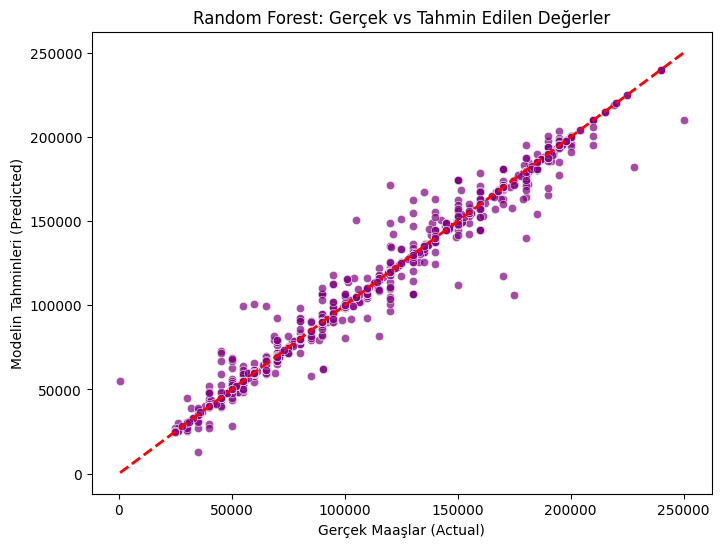

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2) # İdeal çizgi (y=x)
plt.xlabel("Gerçek Maaşlar (Actual)")
plt.ylabel("Modelin Tahminleri (Predicted)")
plt.title("Random Forest: Gerçek vs Tahmin Edilen Değerler")
plt.show()

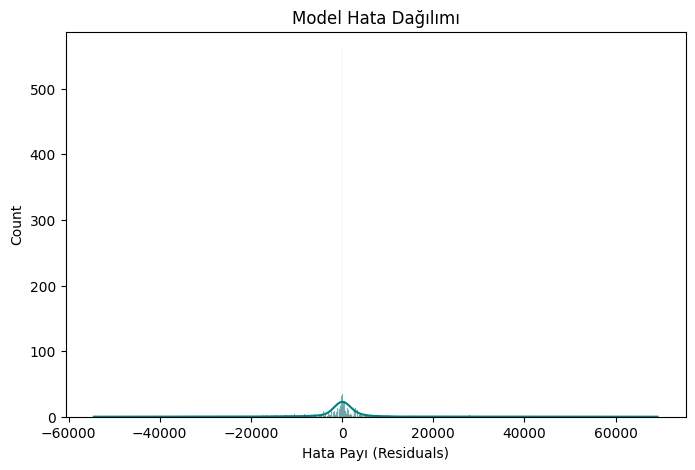

In [11]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True, color='teal')
plt.xlabel("Hata Payı (Residuals)")
plt.title("Model Hata Dağılımı")
plt.show()

/tmp/ipykernel_51/4148958178.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='magma')


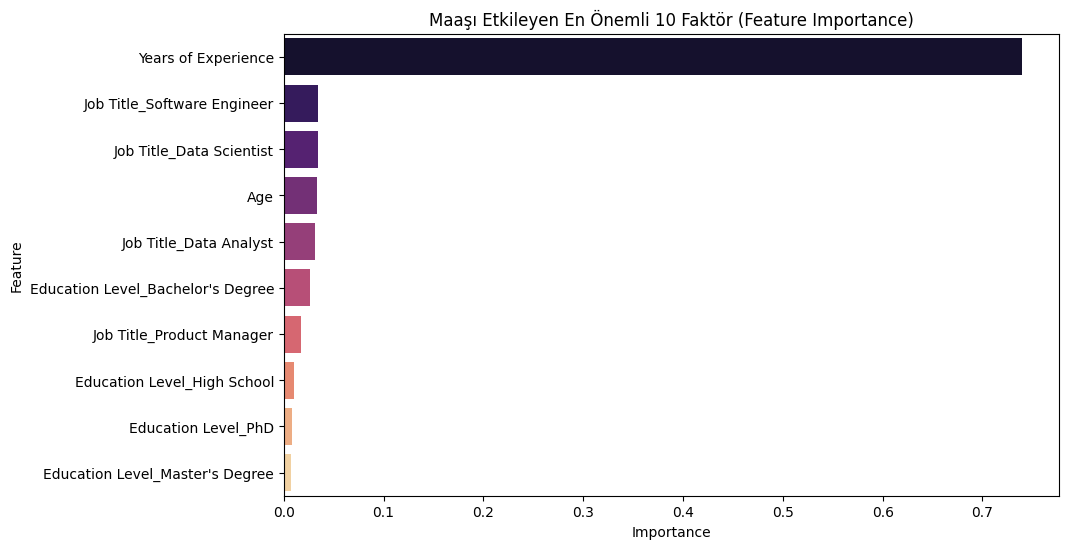

<Axes: xlabel='Importance', ylabel='Feature'>

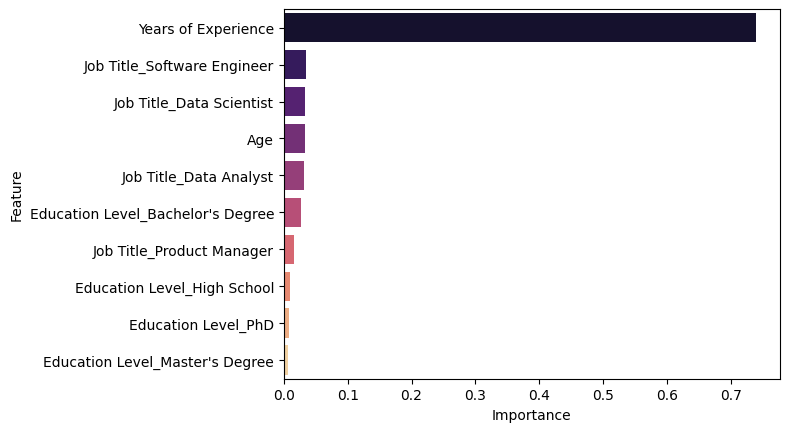

In [13]:
import numpy as np

importances = rf.feature_importances_
feature_names = X.drop(columns=['Salary']).columns if 'Salary' in X.columns else X.columns

feature_imp_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False).head(10) # En önemli ilk 10 özellik

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='magma')
plt.title("Maaşı Etkileyen En Önemli 10 Faktör (Feature Importance)")
plt.show()